# Orthomosaic Example Series

Turn a set of overlapping drone photos into a georeferenced **orthomosaic** — and then into published map tiles and segmented objects — entirely on Databricks, with GeoBrix carrying the spatial work. Structure-from-Motion (SfM) recovers where each photo was taken and reconstructs the scene in 3D; that reconstruction is stitched into a top-down image, color-corrected, tiled for the web, and segmented into objects and land cover.

![Orthomosaic series overview — config_nb, 01a sparse SfM (CPU), 01b dense MVS (GPU, optional), 02_publish, 03_segment](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/orthomosaic/orthomosaic-overview.png)

The series is **five notebooks that share one configuration** (`config_nb`), run in order:

- **`config_nb`** — shared configuration and helper functions (GPS clustering, camera / GSD parameters, output paths). `%run`-imported by every other notebook; not run on its own.
- **`01a` — Sparse SfM (CPU) · _this notebook_** — EXIF/GPS metadata (`exif_gbx`) → quality control → GPS pair discovery (`ST_DistanceSphere`) → distributed feature matching → `pycolmap` incremental mapping → a **sparse model + sparse orthomosaic**. The shared foundation the rest of the series builds on.
- **`01b` — Dense MVS (GPU, optional)** — densifies 01a's sparse model into a dense point cloud, a **dense orthomosaic + DSM**, and a merged LAZ.
- **`02_publish`** — color-corrects the orthomosaic and writes a **COG + PMTiles** for web maps.
- **`03_segment`** — **GeoSAM** instance segmentation + land-cover classification, served behind the Unity Gateway as a Model Serving endpoint.
- **`monitor`** — a lightweight watcher for live SfM progress while 01a runs.

You are here: **01a**.

# Orthomosaic — Part 1a: Sparse SfM (CPU) → Orthomosaic GeoTIFF

![01a — sparse SfM: EXIF/GPS QC, distributed matching, incremental mapping, sparse orthomosaic](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/orthomosaic/orthomosaic-01a.png)

**Download drone images, extract metadata with `exif_gbx`, quality-control them with imagery scalars, and run distributed sparse SfM (pycolmap) to produce a georeferenced orthomosaic GeoTIFF.**

The pipeline combines GeoBrix data-source and scalar APIs with Databricks built-in geospatial functions:

- **GeoBrix `exif_gbx`** reads per-file EXIF + GPS metadata at scale (mode `"qc"` also computes sharpness and brightness without a second image decode).
- **GeoBrix `gsd_from_telemetry`** computes ground sampling distance from altitude, focal length, sensor size, and image width.
- **Databricks `ST_DistanceSphere`** filters image pairs by GPS distance — keeps pair count linear in image count instead of O(n²) exhaustive.

The `GROUP_KEY_COL` seam (config `"_group"`) enables multi-flight runs: set it to a metadata column (e.g. derived from `timestamp`) and the pipeline emits one orthomosaic per distinct value.

> **Runtime.** Runs on **Serverless environment 5**, CPU sparse SfM. The GPU variant is **Part 1b** (`01b_sfm_orthomosaic_gpu`).

---

**Last Update:** September 30, 2026

## Setup

In [0]:
# Install GeoBrix (Serverless, env 5).
%pip install --quiet --disable-pip-version-check --no-deps --force-reinstall "geobrix @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env5-py3-none-any.whl"
%pip install --quiet "geobrix[vizx] @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env5-py3-none-any.whl"
%pip install --quiet "pycolmap==4.2.1"
%restart_python

GeoBrix 0.6.0+env5 installed (build b5dbc078163e, wheel sha256 0678680b2802) on Serverless environment 5


In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: heavy (Catalyst) unavailable: Spark Connect session (Serverless); using light (48 functions)
geobrix: SQL unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using light


### Optional: a faster “taste” of the pipeline (opt-in)

By **default this notebook builds the FULL sparse reconstruction** from *all* your images — that is what **Part 1b** then densifies into the full orthomosaic. If you'd rather start with a quick, lower-fidelity preview before committing to the full run, uncomment the settings in the next cell to build a **minimal** sparse model: one GPS cluster, capped to its first 8 images.

Pair this with the matching opt-in near the top of **Part 1b** for an end-to-end “taste” in a fraction of the time. Leave both commented for the full experience.

In [0]:
# --- Optional dev "taste": build a MINIMAL sparse model instead of the full one ---
# Uncomment BOTH to cap to one cluster's first 8 images (fast, lower-fidelity preview;
# pair with the matching opt-in in nb1b). Leave commented (default) for the FULL run.
# DEV_MAX_IMAGES = 8      # cap each reconstructed cluster to its first 8 images
# SUBSET_CLUSTER = 0      # reconstruct only GPS cluster 0

## Stage the image dataset (idempotent)

Download the [Old Orchard DroneDB dataset](https://hub.dronedb.app/r/odm/old-orchard) from
GitHub to the series' Volume (`DOWNLOAD_DIR` in `config_nb`), where `exif_gbx` and the
Serverless workers read them. The `FORCE_DOWNLOAD=False` guard skips the fetch when images are already staged.

In [0]:
import time as _time_import  # time imported in config_nb; alias for clarity

img_path = str(Path(DOWNLOAD_DIR).resolve())

# Per-file staging: always fetch the authoritative GitHub listing, then download
# only the images MISSING locally (fill gaps in a partial download) instead of
# skipping wholesale when >=1 file is already present. FORCE_DOWNLOAD=True
# re-fetches every file even if present; otherwise each file already on disk is
# kept. (Lists the repo every run via the cheap contents API so an incomplete
# local set is completed rather than skipped.)
_t = _time_import.perf_counter()
image_files = [f for f in iter_repo_files(GH_DATASET_PATH) if is_image(f["path"])]
_fetched = _kept = 0
for fi in image_files:
    _out = Path(DOWNLOAD_DIR) / Path(fi["path"]).relative_to(GH_DATASET_PATH)
    if _out.exists() and not FORCE_DOWNLOAD:
        _kept += 1
        continue
    download_file(fi, DOWNLOAD_DIR, force=FORCE_DOWNLOAD)
    _fetched += 1
staged = [p for p in Path(DOWNLOAD_DIR).rglob("*") if p.suffix.lower() in (".jpg", ".jpeg")]
print(f"{len(image_files)} source images: {_fetched} fetched "
      f"({'FORCE_DOWNLOAD' if FORCE_DOWNLOAD else 'missing-only'}), {_kept} kept; "
      f"{len(staged)} staged at {img_path} in {_time_import.perf_counter()-_t:.1f}s")

171 source images: 0 fetched (missing-only), 171 kept; 171 staged at /Volumes/geospatial_docs/orthomosaic/data/gopro/images/OldOrchard_2017-07-22 in 2.9s


## Preview: the raw input images (the “before”)

Before any processing, the input is just a pile of **overlapping drone photos** — each
carries per-image GPS but has no alignment to its neighbors or to the ground. The contact
sheet below samples the raw frames so the challenge is visible: Structure-from-Motion must
recover every camera’s pose and a sparse 3-D scene, which we then back-project into a
single georeferenced orthomosaic.

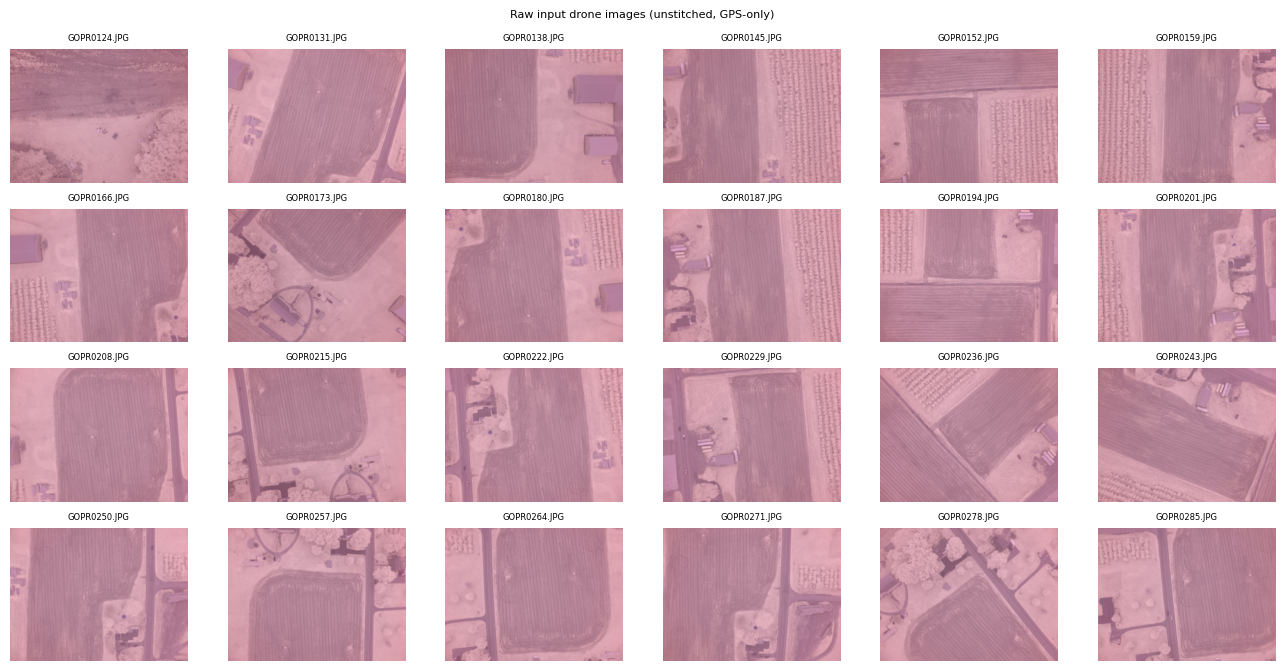

In [0]:
# Contact sheet of the raw inputs: an evenly-spaced sample of the overlapping,
# GPS-only drone frames that SfM must align and stitch. vz.plot_gallery previews
# any image/raster collection as a thumbnail grid (the small-multiples of plot_file).
_ = vz.plot_gallery(
    img_path,
    mode="sample",
    limit=24,
    cols=6,
    title="Raw input drone images (unstitched, GPS-only)",
)

## Extract EXIF + GPS metadata with GeoBrix `exif_gbx`

**GeoBrix `exif_gbx`** — a Serverless-safe DataSource V2 reader — extracts per-file EXIF
metadata, GPS coordinates (as WKB geometry), focal length, sensor width, and image
dimensions without hand-rolling PIL loops.

`mode="qc"` additionally computes `sharpness` and `brightness` pixel metrics in the same
pass (no second image decode), saving one full round-trip over the file set.

In [0]:
import time as _t_exif

_t0 = _t_exif.perf_counter()
try:
    # Auto-detect the collection's COMMON EXIF intrinsics (uniform focal + a
    # camera-model sensor-width lookup) and surface an evaluation of what is
    # common / present-but-variable / missing. Explicit config still wins.
    from databricks.labs.gbx.ds.exif import build_exif_common_opts
    _exif_opts, _exif_report = build_exif_common_opts(img_path, mode="sample", limit=24)
    _exif_opts["mode"] = "qc"
    if SENSOR_WIDTH_MM is not None:
        _exif_opts["sensorWidthMm"] = str(SENSOR_WIDTH_MM)
    if FOCAL_LENGTH_MM is not None:
        _exif_opts["focalLengthMm"] = str(FOCAL_LENGTH_MM)
    print("[exif] common opts:", _exif_opts)
    print("[exif] classification:", _exif_report["classification"])
    for _s in _exif_report["suggestions"]:
        print("   [exif] suggestion:", _s)

    # spark.read.format("exif_gbx") — one row per image; no PIL loop needed.
    df_meta = (
        spark.read.format("exif_gbx")
             .options(**_exif_opts)
             .load(img_path)
    )

    # Add group key: default constant group so the pipeline runs as one batch.
    # Change GROUP_KEY_COL and assign a real column here for multi-group runs.
    if GROUP_KEY_COL == "_group":
        df_meta = df_meta.withColumn("_group", F.lit("all"))
    # else: GROUP_KEY_COL already exists in the schema (e.g. derived from timestamp)

    print(f"exif_gbx: {df_meta.count()} images read in {_t_exif.perf_counter()-_t0:.1f}s")
    df_meta.select(
        "path", "latitude", "longitude", "altitude",
        "focal_length_mm", "sensor_width_mm", "image_width", "image_height",
        "sharpness", "brightness",
    ).show(5, truncate=60)
except Exception as e:
    print(f"[ERROR] exif_gbx step failed after {_t_exif.perf_counter()-_t0:.1f}s: {e}")
    raise

[exif] common opts: {'focalLengthMm': '3.0', 'mode': 'qc', 'sensorWidthMm': '6.17'}
[exif] classification: {'common': {'focal_length_mm': 3.0, 'camera_make': 'GoPro', 'camera_model': 'HERO4 Black', 'image_width': 4000, 'image_height': 3000}, 'variable': {'latitude': {'n_distinct': 24, 'examples': [43.229196400063856, 43.22934350004819, 43.229345400013955, 43.22935070001784, 43.22970330003028, 43.229724000000004]}, 'longitude': {'n_distinct': 24, 'examples': [-77.9667395, -77.9665736999626, -77.9665408, -77.96640509989486, -77.96633609998092, -77.966241799918]}, 'altitude': {'n_distinct': 24, 'examples': [153.91, 256.18, 256.36, 256.59, 256.89, 257.42]}, 'timestamp': {'n_distinct': 24, 'examples': [datetime.datetime(2015, 1, 1, 0, 3, 56), datetime.datetime(2015, 1, 1, 0, 4, 44), datetime.datetime(2015, 1, 1, 0, 5, 1), datetime.datetime(2015, 1, 1, 0, 5, 14), datetime.datetime(2015, 1, 1, 0, 5, 26), datetime.datetime(2015, 1, 1, 0, 5, 40)]}}, 'missing': {'sensor_width_mm': 0.0}}
   [exif

## Quality-control filter

Remove blurry or underexposed images before SfM.

- **Sharpness** — keep images with sharpness ≥ 50% of the batch median.
- **Brightness** — keep images in the range [20, 240] (discard over- and under-exposed).

The `sharpness` and `brightness` columns were populated by `exif_gbx` mode `"qc"` using the
same `image_sharpness` / `image_brightness` scalars from `databricks.labs.gbx.rasterx.imagery`.

In [0]:
import time as _t_qc

_t0 = _t_qc.perf_counter()
try:
    window_spec = Window.partitionBy(GROUP_KEY_COL)
    df_qc = (
        df_meta
        .withColumn("median_sharpness", F.percentile_approx("sharpness", 0.5).over(window_spec))
        .filter(F.col("sharpness") >= F.col("median_sharpness") * 0.5)
        .filter((F.col("brightness") > 20) & (F.col("brightness") < 240))
        .withColumn("gps_geom", F.expr("st_point(longitude, latitude)"))
        .withColumnRenamed("path", "source")
    )
    n_before = df_meta.count()
    n_after  = df_qc.count()
    print(f"QC filter: {n_before} → {n_after} images retained "
          f"({n_before - n_after} removed) in {_t_qc.perf_counter()-_t0:.1f}s")
except Exception as e:
    print(f"[ERROR] QC filter failed after {_t_qc.perf_counter()-_t0:.1f}s: {e}")
    raise

QC filter: 171 → 171 images retained (0 removed) in 80.5s


## Validate GPS coverage

Warn before SfM if fewer than 3 images have valid GPS — incremental mapping will proceed
but without GPS-constrained bundle adjustment, which reduces georeferencing accuracy.

In [0]:
gps_ok_count = df_qc.filter(
    F.col("latitude").isNotNull() & F.col("longitude").isNotNull() & F.col("altitude").isNotNull()
).count()
total_count = df_qc.count()
print(f"GPS coverage: {gps_ok_count}/{total_count} images have valid lat/lon/altitude")
if gps_ok_count < 3:
    print("[WARN] Fewer than 3 images have GPS — incremental mapping will proceed without "
          "GPS-constrained BA. Georeferencing accuracy may be reduced.")

GPS coverage: 171/171 images have valid lat/lon/altitude


## Run distributed SfM (one orthomosaic per `GROUP_KEY_COL` value)

For each distinct value of `GROUP_KEY_COL`, collect the image subset and run
`sfm.run_sfm` (from `databricks.labs.gbx.rasterx.sfm`) — feature extraction, geospatial
pair discovery, distributed matching, and incremental mapping via `pycolmap`.
A GPS cluster that does not reconstruct is dropped (a `[DROP]` line) and the other clusters
continue. If no cluster of a group reconstructs, the cell stops with an error.

The `GROUP_KEY_COL = "_group"` default runs all images as a single group.
Set `GROUP_KEY_COL` to a metadata column (e.g. `"flight_date"`) and pass a real column
value to run the pipeline for each flight.

In [0]:
import time as _t_sfm
from databricks.labs.gbx.rasterx.imagery import cluster_by_gps

# Per group: partition images into RAM-bounded GPS clusters, then run SfM per
# cluster. Peak driver RAM = one cluster reconstruction, not the whole scene.
# Feature extraction can hit a Serverless worker OOM (concurrent SIFT on a node).
# Retry protocol: up to 4 tries; the first retries re-run as-is (a
# transient OOM often clears), and after 2 failures extraction is SERIALIZED to
# one partition (one SIFT at a time, memory-bounded) for the remaining tries.
# Skip a cluster only as a last resort.
# Dev: --set-var SUBSET_CLUSTER=<idx> runs only that GPS cluster (fast GPU dense
# iteration); unset = all clusters. globals().get keeps a runner-injected override.
SUBSET_CLUSTER = globals().get("SUBSET_CLUSTER", None)
# Dev: --set-var FORCE_SERIALIZE=True forces serialized (coalesce-1) extraction
# from try 1 (isolates the memory-bounded path; skips the 2 parallel attempts).
_FORCE_SERIALIZE = bool(globals().get("FORCE_SERIALIZE", False))
def _extract_mode(_t):
    return "serialized" if (_t > 2 or _FORCE_SERIALIZE) else "parallel"
cluster_models = {}   # group -> {cluster_id: (sparse_dir, gps_json)}
_sfm_diag = []   # per-cluster outcome (registered / DROP reason); --set-var SFM_DIAG=1 to surface
groups = [row[GROUP_KEY_COL] for row in df_qc.select(GROUP_KEY_COL).distinct().collect()]
print(f"Running clustered SfM for {len(groups)} group(s): {groups}")

_MAX_TRIES = 4
for grp in groups:
    _t0 = _t_sfm.perf_counter()
    print(f"\n=== Group: {grp} ===")
    df_grp = df_qc.filter(F.col(GROUP_KEY_COL) == grp)
    # cluster_by_gps runs on the small per-image telemetry table (driver-side).
    _pdf = df_grp.select("source", "latitude", "longitude").toPandas()
    _clustered = cluster_by_gps(
        _pdf,
        target_cluster_images=TARGET_CLUSTER_IMAGES,
        overlap_frac=CLUSTER_OVERLAP_FRAC,
        min_cluster_images=MIN_CLUSTER_IMAGES,
    )
    _cids = sorted(_clustered["_cluster"].unique())
    print(f"  {len(_pdf)} images \u2192 {len(_cids)} GPS cluster(s) "
          f"(target\u2248{TARGET_CLUSTER_IMAGES}, overlap={CLUSTER_OVERLAP_FRAC})")
    cluster_models[grp] = {}
    _run_cids = ([_cids[SUBSET_CLUSTER]]
                 if SUBSET_CLUSTER is not None and SUBSET_CLUSTER < len(_cids) else _cids)
    for cid in _run_cids:
        _srcs = _clustered.loc[_clustered["_cluster"] == cid, "source"].tolist()
        # Dev: --set-var DEV_MAX_IMAGES=N caps this cluster to its first N images so
        # sparse+dense iterate in minutes (small chunk); scratch/persist get a _devN
        # suffix so dev never collides with the full persisted model.
        _dev_n = globals().get("DEV_MAX_IMAGES", None)
        _devsuf = ""
        if _dev_n:
            # sorted() -> deterministic capture-order (spatially contiguous) frames so the
            # dev subset reliably overlaps for matching; an arbitrary first-N from the
            # toPandas() order can pick scattered frames -> 0 matches -> dropped cluster.
            _srcs = sorted(_srcs)[: int(_dev_n)]
            _devsuf = f"_dev{int(_dev_n)}"
            print(f"  [dev] DEV_MAX_IMAGES={int(_dev_n)}: cluster {cid} \u2192 first {len(_srcs)} images")
        df_cluster = df_grp.filter(F.col("source").isin(_srcs))
        _co = f'{group_paths(grp)["sfm_dir"]}/cluster_{cid}{_devsuf}'  # local SfM scratch (SQLite-safe)
        _attempts = []   # per-try trace (mode/secs/outcome) surfaced in SFM_DIAG
        for _try in range(1, _MAX_TRIES + 1):
            _ct0 = _t_sfm.perf_counter()
            try:
                res = sfm.run_sfm(
                    spark,
                    df_qc=df_cluster,
                    image_dir=img_path,
                    output_dir=_co,
                    group_key=f"{grp}_c{cid}{_devsuf}",
                    feature_table=f"{CATALOG_NAME}.{SCHEMA_NAME}.extracted_features_{grp}_c{cid}{_devsuf}",
                    match_table=f"{CATALOG_NAME}.{SCHEMA_NAME}.verified_matches_{grp}_c{cid}{_devsuf}",
                    max_pair_dist_m=MAX_PAIR_DIST_M,
                    force_features=FORCE_RELOAD or _try > 1,
                    force_matches=FORCE_RELOAD or _try > 1,
                    force_master=FORCE_RELOAD or _try > 1,
                    persist_dir=f'{group_paths(grp)["sfm_persist"]}/cluster_{cid}{_devsuf}',
                    serialize_extract=(_try > 2) or _FORCE_SERIALIZE,
                )
                cluster_models[grp][cid] = (res["sparse_dir"], res["gps_json"])
                _attempts.append({"try": _try, "mode": _extract_mode(_try),
                                  "secs": round(_t_sfm.perf_counter() - _ct0, 1), "status": "ok"})
                _sfm_diag.append({"grp": str(grp), "cid": int(cid), "n_imgs": len(_srcs),
                                  "registered": res.get("registered"), "status": "ok",
                                  "attempts": _attempts})
                print(f"  cluster {cid}: {len(_srcs)} imgs, {res.get('registered')} registered "
                      f"in {_t_sfm.perf_counter()-_ct0:.0f}s")
                break
            except Exception as e:
                _m = str(e)
                _transient = ("OOM" in _m) or ("out of memory" in _m.lower()) or ("worker exited" in _m)
                _attempts.append({"try": _try, "mode": _extract_mode(_try),
                                  "secs": round(_t_sfm.perf_counter() - _ct0, 1),
                                  "status": "oom" if _transient else "error", "err": _m[:80]})
                if _transient and _try < _MAX_TRIES:
                    # After 2 failures, the next tries SERIALIZE extraction (1 partition,
                    # one SIFT at a time) so a node never runs concurrent SIFT. Announce it.
                    _serial_next = (_try + 1) > 2
                    _mode = ("SERIALIZED extraction (1 partition, memory-bounded)"
                             if _serial_next else "re-extract")
                    print(f"  [retry {_try}/{_MAX_TRIES-1}] cluster {cid} worker OOM "
                          f"after {_t_sfm.perf_counter()-_ct0:.0f}s \u2014 backoff + {_mode}"
                          + ("  <- switching to serialized after 2 fails" if _serial_next else ""))
                    _t_sfm.sleep(15)
                    continue
                print(f"  [DROP] cluster {cid} ({len(_srcs)} images) did not reconstruct "
                      f"after {_try} attempt(s): {_m[:180]}. The other clusters continue.")
                _sfm_diag.append({"grp": str(grp), "cid": int(cid), "n_imgs": len(_srcs),
                                  "status": "DROP", "err": _m[:200], "attempts": _attempts})
                break
    _nmods = len(cluster_models[grp])
    print(f"Group {grp!r}: {_nmods} cluster model(s) in {_t_sfm.perf_counter()-_t0:.0f}s")

if globals().get("SFM_DIAG"):
    import json as _json
    dbutils.notebook.exit(_json.dumps(_sfm_diag))

# A dropped cluster leaves a gap; a group with NO cluster model has no orthomosaic at all.
_empty = [g for g in groups if not cluster_models[g]]
if _empty:
    raise RuntimeError(
        f"SfM reconstructed no cluster for group(s) {_empty}: every cluster was dropped "
        f"(see the [DROP] lines above). Check that the images under {img_path} are readable."
    )

Running clustered SfM for 1 group(s): ['all']

=== Group: all ===
  171 images → 4 GPS cluster(s) (target≈55, overlap=0.3)
[sfm] could not set spark.sql.execution.arrow.maxRecordsPerBatch=1 on this session; extraction uses the default batch size (more images per batch, so more memory per task)
[Stage 1] extracted features: 66.2s | 53 images
Geospatial filtering reduced pairs to: 267
[Stage 2-3] Pair matching: 76.8s | 267 verified pairs
  GPS priors available: 53 images


I20261112 07:22:43.763603 139723850647232 feature_extraction.cc:498] === Feature extraction ===
I20261112 07:22:43.763902 139723603441344 sift.cc:764] Creating SIFT CPU feature extractor
I20261112 07:22:43.764083 139723850647232 timer.cc:90] Elapsed time: 0.000 [minutes]


  Master DB: 53 images, GPS=True, best init pair: 10/11
Running incremental mapping (53 images)...


I20261112 07:22:52.118943 139727159287936 incremental_pipeline.cc:353] Loading database
I20261112 07:22:52.119026 139727159287936 database_cache.cc:82] Loading rigs...
I20261112 07:22:52.119059 139727159287936 database_cache.cc:92]  1 in 0.000s
I20261112 07:22:52.119068 139727159287936 database_cache.cc:100] Loading cameras...
I20261112 07:22:52.119081 139727159287936 database_cache.cc:118]  1 in 0.000s
I20261112 07:22:52.119085 139727159287936 database_cache.cc:126] Loading frames...
I20261112 07:22:52.119177 139727159287936 database_cache.cc:136]  53 in 0.000s
I20261112 07:22:52.119180 139727159287936 database_cache.cc:144] Loading matches...
I20261112 07:22:52.125445 139727159287936 database_cache.cc:163]  267 in 0.006s
I20261112 07:22:52.125480 139727159287936 database_cache.cc:171] Loading images...
I20261112 07:22:52.141279 139727159287936 database_cache.cc:268]  53 in 0.016s (connected 53, loaded 53)
I20261112 07:22:52.141769 139727159287936 database_cache.cc:282] Loading pose p

[Mapping] Initial pair found — registering remaining images...


I20261112 07:22:53.728835 139727159287936 incremental_pipeline.cc:620] Registering image #22 (num_reg_frames=2)
I20261112 07:22:53.728969 139727159287936 incremental_pipeline.cc:623] => Image sees 5876 / 10527 points
I20261112 07:22:55.299435 139727159287936 incremental_pipeline.cc:88] Retriangulation and Global bundle adjustment
W20261112 07:22:55.316033 139727159287936 alignment.cc:286] No pose priors with valid covariance found.
W20261112 07:22:55.335891 139727159287936 bundle_adjustment_ceres.cc:1080] Alignment w.r.t. prior positions failed


... (483 outputs left out)

I20261112 08:09:38.779386 139727159287936 incremental_pipeline.cc:620] Registering image #3 (num_reg_frames=49)
I20261112 08:09:38.779432 139727159287936 incremental_pipeline.cc:623] => Image sees 2875 / 3044 points


[Mapping] 48/50 images (96%) | elapsed 180s | ETA ~8s


I20261112 08:09:39.835009 139727159287936 incremental_pipeline.cc:88] Retriangulation and Global bundle adjustment
W20261112 08:09:39.954732 139727159287936 alignment.cc:286] No pose priors with valid covariance found.
W20261112 08:09:46.121629 139727159287936 alignment.cc:286] No pose priors with valid covariance found.
I20261112 08:09:52.170433 139727159287936 incremental_pipeline.cc:88] Retriangulation and Global bundle adjustment
W20261112 08:09:52.265445 139727159287936 alignment.cc:286] No pose priors with valid covariance found.
I20261112 08:09:58.276563 139727159287936 incremental_pipeline.cc:826] Keeping successful reconstruction
W20261112 08:09:58.280290 139727159287936 alignment.cc:286] No pose priors with valid covariance found.
I20261112 08:09:58.320509 139727159287936 timer.cc:90] Elapsed time: 3.308 [minutes]


[Stage 4-5] SfM complete: 1 model(s) in 205s (48/50 images registered).
[Stage 4-5] Persisted SfM → /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/sfm/cluster_3 (reusable on FORCE_RELOAD=False)
  cluster 3: 50 imgs, 48 registered in 578s
Group 'all': 4 cluster model(s) in 3025s


## Compute GSD via GeoBrix `gsd_from_telemetry`

**GeoBrix `gsd_from_telemetry`** computes ground sampling distance in cm/pixel from
altitude (m), focal length (mm), sensor width (mm), and image width (px) using the
standard pinhole-camera formula:

```
GSD (cm/px) = sensor_mm × alt_m × 100 / (focal_mm × width_px)
```

This matches the formula used by OpenDroneMap and COLMAP documentation.

In [0]:
import time as _t_gsd

_t0 = _t_gsd.perf_counter()
try:
    # Use exif_gbx columns (sensor_width_mm, focal_length_mm) + config override fallbacks.
    _sw_col = F.coalesce(F.col("sensor_width_mm"), F.lit(SENSOR_WIDTH_MM))
    _fl_col = F.col("focal_length_mm") if FOCAL_LENGTH_MM is None else F.lit(FOCAL_LENGTH_MM)

    df_gsd = df_qc.withColumn(
        "gsd_cm",
        gsd_udf(
            F.col("altitude").cast("double"),
            _fl_col.cast("double"),
            _sw_col.cast("double"),
            F.col("image_width").cast("double"),
        ),
    )
    stats   = df_gsd.agg(F.avg("gsd_cm"), F.min("gsd_cm"), F.max("gsd_cm")).collect()[0]
    avg_gsd = stats[0]
    print(f"GSD: avg={avg_gsd:.2f} cm/px  min={stats[1]:.2f}  max={stats[2]:.2f}  "
          f"({_t_gsd.perf_counter()-_t0:.1f}s)")

    # Use config GSD_CM if set; otherwise auto-derive from image telemetry.
    gsd_for_ortho = GSD_CM if GSD_CM is not None else round(avg_gsd, 1)
    print(f"Using GSD_CM={gsd_for_ortho:.1f} cm/px for orthomosaic rendering.")
except Exception as e:
    print(f"[ERROR] GSD step failed after {_t_gsd.perf_counter()-_t0:.1f}s: {e}")
    raise

GSD: avg=13.26 cm/px  min=7.91  max=13.40  (49.4s)
Using GSD_CM=13.3 cm/px for orthomosaic rendering.


## Build the orthomosaic GeoTIFF

Convert the COLMAP sparse reconstruction into a georeferenced RGB GeoTIFF via
`ortho.sparse_orthomosaic`.  The canvas-RAM guard warns before allocating the float16 canvas
if the estimated memory exceeds ~4 GB (50% of typical Serverless 8 GB driver RAM).

Each group's mosaic is **checkpointed per-group**: if `orthomosaic.tif` already exists with a matching input signature (sparse models + blend knobs), that group is skipped on re-run.  Set `FORCE_MOSAIC = True` in `config_nb` to recompute regardless.

In [0]:
import time as _t_ortho
from databricks.labs.gbx.rasterx import checkpoint as ckpt

_t0 = _t_ortho.perf_counter()
try:
    # One blended orthomosaic per group: the group's GPS clusters are aligned to a
    # shared ENU frame and accumulated into a single canvas, written under group_<grp>/.
    ortho_paths = {}
    for grp in groups:
        cmods = cluster_models.get(grp, {})
        if not cmods:
            print(f"[WARN] group {grp!r}: no cluster models — skipping ortho")
            continue
        _gp = group_paths(grp)
        _mani = ckpt.Manifest(_gp["checkpoint"])
        _nclust = len(cmods)
        _bin_total = sum(
            (Path(sd) / "images.bin").stat().st_size
            for sd, _ in cmods.values()
            if (Path(sd) / "images.bin").exists()
        )
        _sig = ckpt.input_signature(
            {"grp": grp, "n_clusters": _nclust, "sparse_bin_total": _bin_total},
            {"gsd_cm": GSD_CM, "nadir": NADIR, "blend_gamma": BLEND_GAMMA},
        )
        if ckpt.checkpoint_skip(_mani, "mosaic", grp, _sig, force=bool(FORCE_MOSAIC)):
            print(f"[mosaic][skip] group {grp!r} — checkpointed ({_gp['ortho']})")
            ortho_paths[grp] = _gp["ortho"]
            continue
        Path(_gp["ortho"]).parent.mkdir(parents=True, exist_ok=True)
        ortho.sparse_orthomosaic(
            cluster_models=cmods,
            image_dir=img_path,
            out_tiff=_gp["ortho"],
            gsd_cm=gsd_for_ortho,
            max_workers=MAX_ORTHO_WORKERS,
            blend_gamma=BLEND_GAMMA,
        )
        ortho_paths[grp] = _gp["ortho"]
        _mani.mark_done("mosaic", grp, _sig, _gp["ortho"])
    print(f"Orthomosaic(s) built in {_t_ortho.perf_counter()-_t0:.0f}s → {list(ortho_paths.values())}")
except Exception as e:
    print(f"[ERROR] Orthomosaic build failed after {_t_ortho.perf_counter()-_t0:.1f}s: {e}")
    raise

[place] cluster 2: tied via 30 shared cameras
[place] cluster 0: tied via 22 shared cameras
[place] cluster 3: tied via 20 shared cameras
[place] 4/4 clusters placed in shared ENU (3 via shared cameras, anchor 1)
Canvas: 2525x4172px @ 13.3cm (0.08 GB float16) from 4 cluster(s)
[ortho] cluster 1: projected (71 images total)
[ortho] cluster 2: projected (139 images total)
[ortho] cluster 0: projected (192 images total)
[ortho] cluster 3: projected (242 images total)
Coverage: 62.3% (242 images projected)
Orthomosaic written: /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/orthomosaic.tif (387s)
Orthomosaic(s) built in 387s → ['/Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/orthomosaic.tif']


## Visualize

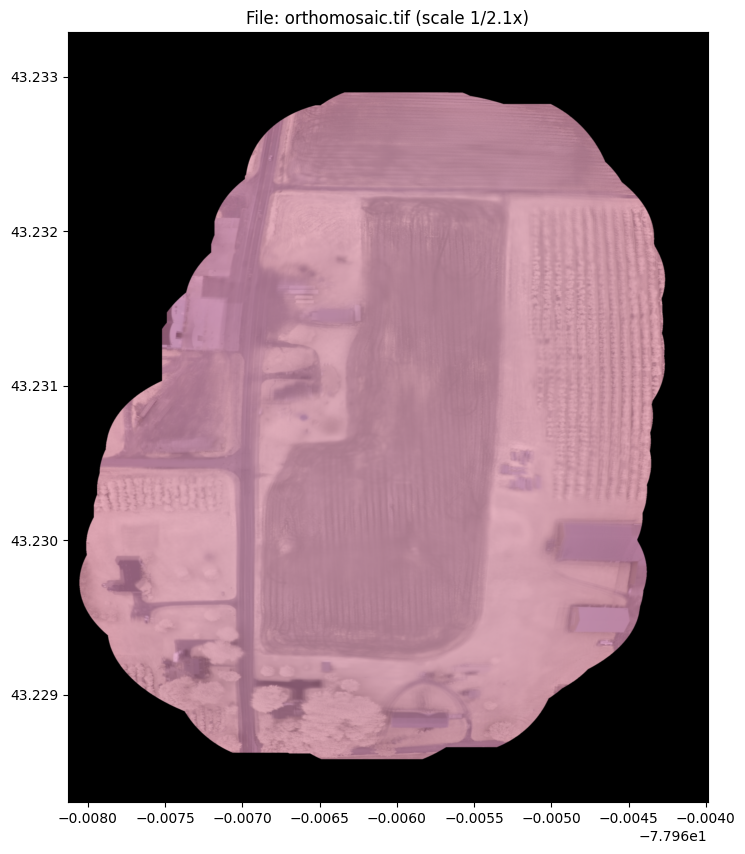

In [0]:
from pathlib import Path as _P
_shown = [g for g in groups if _P(group_paths(g)["ortho"]).exists()]
if _shown:
    vz.plot_file(group_paths(_shown[0])["ortho"])
else:
    print("[skip] no orthomosaic produced this run (no cluster reconstructed)")

## Steps performed

1. **Download** — fetched the Old Orchard drone imagery from GitHub (idempotent).
2. **EXIF/GPS extraction** — `exif_gbx` (GeoBrix) read metadata + sharpness/brightness in one pass.
3. **QC filter** — retained images above the per-group sharpness p50 × 0.5 and within the brightness window.
4. **GPS validation** — warned when fewer than 3 images have valid altitude.
5. **Distributed SfM** — feature extraction, `ST_DistanceSphere` (Databricks) pair discovery, distributed matching, and incremental mapping via `pycolmap`.
6. **GSD** — computed via `gsd_from_telemetry` (GeoBrix) from altitude, focal length, sensor size, and image width.
7. **Orthomosaic** — back-projected all registered images onto the COLMAP ground plane; wrote an EPSG:4326 GeoTIFF.

**Next:** Part 2 applies per-channel percentile color correction to remove sensor cast.

**This notebook produced the sparse orthomosaic** (your deliverable). To get a *dense* orthomosaic, also run **Part 1b** on GPU compute — it loads this notebook's persisted sparse model and runs dense MVS. Downstream notebooks (Part 2 color+COG, Part 3 PMTiles) consume `ortho_input(grp)`, which automatically uses the dense ortho if Part 1b produced one, else this sparse ortho.